# ADSP 31014 — Statistical Models for Data Science
## Homework 2

**Name:** Obaro Erigha    
**Term:** Autumn 2026    

**External Sources:** Claude for Q3 as requested

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.options.display.float_format = '{:,.6f}'.format

## Question 1a: Intercept only, MSE

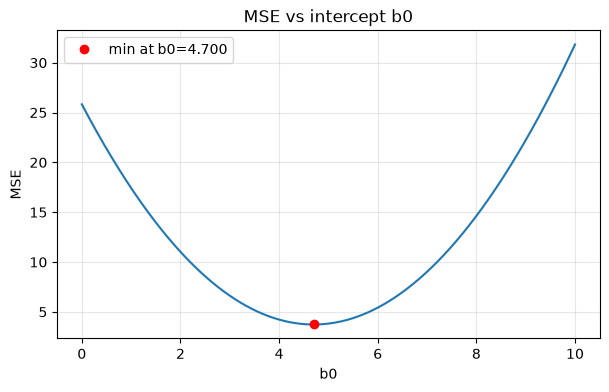

Minimum MSE value     : 3.736000
b0 attaining minimum  : 4.7000
mean(y)               : 4.7000
Does optimal b0 equal mean(y)? True


In [ ]:
y = np.array([2, 5, 4.3, 4.2, 8])  # Observed data

def compute_mse(b0):
    return np.mean((y - b0) ** 2)

b0 = np.linspace(0, 10, 10000 + 1)            # Try various b0's
mse = np.array([compute_mse(b) for b in b0])

plt.figure(figsize=(7, 4))
plt.plot(b0, mse)
i = mse.argmin()
plt.plot(b0[i], mse[i], 'ro', label=f'min at b0={b0[i]:.3f}')
plt.xlabel('b0'); plt.ylabel('MSE'); plt.title('MSE vs intercept b0')
plt.legend(); plt.grid(alpha=.3); plt.show()

i = mse.argmin()  # analogue of R's which.min()
print(f"Minimum MSE value     : {mse[i]:.6f}")
print(f"b0 attaining minimum  : {b0[i]:.4f}")
print(f"mean(y)               : {y.mean():.4f}")
print(f"Does optimal b0 equal mean(y)? {np.isclose(b0[i], y.mean())}")

## Question 1b: Intercept-only model

In [3]:
df1 = pd.DataFrame({'y': y})
m1 = smf.ols('y ~ 1', data=df1).fit()
print(m1.summary())
print("Fitted intercept:", m1.params['Intercept'], "  mean(y):", y.mean())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                nan
Time:                        21:39:06   Log-Likelihood:                -10.390
No. Observations:                   5   AIC:                             22.78
Df Residuals:                       4   BIC:                             22.39
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7000      0.966      4.863      0.0

c:\Users\Obaro\miniforge3\envs\data-env\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


## Question 2a: Intercept only, MAE

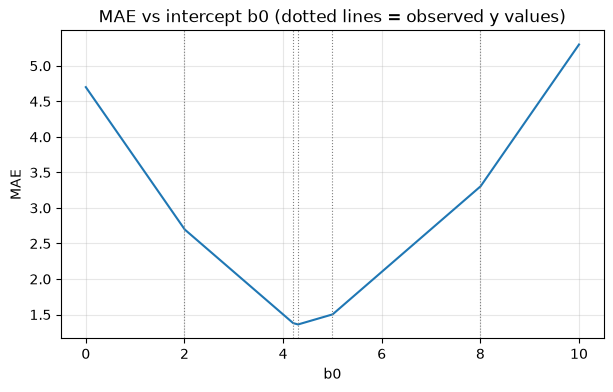

In [4]:
def compute_mae(b0):
    return np.mean(np.abs(y - b0))

mae = np.array([compute_mae(b) for b in b0])

plt.figure(figsize=(7, 4))
plt.plot(b0, mae)
for yi in np.sort(y):
    plt.axvline(yi, color='gray', ls=':', lw=.8)
plt.xlabel('b0'); plt.ylabel('MAE'); plt.title('MAE vs intercept b0 (dotted lines = observed y values)')
plt.grid(alpha=.3); plt.show()

The curve resembles a parabola but is closer to a piecewise linear curve, not a parabola. The slope changes at each observed y value denoted by the dotted lines. 
Between each y value the slope is constant.

## Question 2b: MAE minimizer

In [16]:
j = mae.argmin()
print(f"Minimum MAE value    : {mae[j]:.6f}")
print(f"b0 attaining minimum : {b0[j]:.4f}")
print(f"median(y)            : {np.median(y):.4f}")
print(f"mean(y)              : {y.mean():.4f}")
print("Sorted(y)            :", np.sort(y))

Minimum MAE value    : 1.360000
b0 attaining minimum : 4.3000
median(y)            : 4.3000
mean(y)              : 4.7000
Sorted(y)            : [2.  4.2 4.3 5.  8. ]


The optimal b0 is the sample median of y, not the mean. 

## Question 3: GenAI comparison of MSE vs MAE

Prompt used: "Compare and contrast MSE vs MAE as loss functions for a regression problem. When would you prefer each?"



| Aspect | MSE (L2) | MAE (L1) |
|---|---|---|
| Optimal constant predictor | Mean | Median |
| Estimates | Conditional mean | Conditional median |
| Outlier sensitivity | High (errors squared) | Low (robust) |
| Differentiability | Smooth everywhere | Not differentiable at 0 |
| Optimization | Closed-form solution (OLS); convex, smooth | No closed form; needs LP / IRLS / subgradient methods; convex |
| Units | Squared units of y | Same units as y (easier to interpret) |
| Statistical link | MLE under Gaussian errors | MLE under Laplace errors |
| Solution uniqueness | Unique (if full-rank) | May be non-unique |

**Prefer MSE when:** errors are roughly Gaussian with few outliers; large errors are especially costly (squared penalty); you want fast, closed-form fitting and classical inference (standard errors, t-tests, R²); you care about the mean outcome.

**Prefer MAE when:** the data has outliers or heavy-tailed noise; you want a typical-case (median) prediction; all errors cost proportionally to their size; you want an error metric in the original units.

## Question 4a: Chicago taxi cost vs trip_miles

In [9]:
data = pd.read_csv('C:\\Users\\Obaro\\UChicagoProjects\\Statistical Models for Data Science\\Week2\\Lecture2\\chicago_taxi_trip_sample.csv')
print(data.shape)
print("Missing values:", int(data.isna().sum().sum()))
data[['trip_miles', 'tolls', 'extras', 'trip_total']].describe()

(100000, 17)
Missing values: 0


,trip_miles,tolls,extras,trip_total
count,"100,000.000000","100,000.000000","100,000.000000","100,000.000000"
mean,6.121182,0.001443,1.067526,23.883756
std,6.374934,0.075218,1.897453,18.307585
min,0.010000,0.000000,0.000000,3.250000
25%,1.200000,0.000000,0.000000,10.000000
50%,2.900000,0.000000,0.000000,15.900000
75%,10.600000,0.000000,1.000000,32.750000
max,83.000000,7.000000,20.000000,187.250000


In [10]:
model = smf.ols('trip_total ~ trip_miles', data=data).fit()
print(model.summary())

b0_star = model.params['Intercept']
b1_star = model.params['trip_miles']
print(f"\nFitted equation: y = {b0_star:.4f} + {b1_star:.4f} * x")

                            OLS Regression Results                            
Dep. Variable:             trip_total   R-squared:                       0.797
Model:                            OLS   Adj. R-squared:                  0.797
Method:                 Least Squares   F-statistic:                 3.925e+05
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:53:51   Log-Likelihood:            -3.5291e+05
No. Observations:              100000   AIC:                         7.058e+05
Df Residuals:                   99998   BIC:                         7.058e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.1906      0.036    226.477      0.0

In [17]:
yhat = model.fittedvalues
resid = data['trip_total'] - yhat

mse_fit = np.mean(resid ** 2)
r2 = model.rsquared
corr = np.corrcoef(data['trip_total'], yhat)[0, 1]

print(f"MSE on observed data      : {mse_fit:.6f}")
print(f"R^2                       : {r2:.6f}")
print(f"Corr(Y, Yhat)             : {corr:.6f}")
print(f"Corr(Y, Yhat)^2           : {corr**2:.6f}")
print(f"Corr^2 equals R^2?        : {np.isclose(corr**2, r2)}")

pred10 = model.predict(pd.DataFrame({'trip_miles': [10]}))[0]
print(f"Predicted cost, 10 miles  : ${pred10:.2f}   (check: {b0_star + b1_star*10:.2f})")

print(f"Sum of residuals          : {resid.sum():.3e}")

MSE on observed data      : 68.048760
R^2                       : 0.796969
Corr(Y, Yhat)             : 0.892731
Corr(Y, Yhat)^2           : 0.796969
Corr^2 equals R^2?        : True
Predicted cost, 10 miles  : $33.83   (check: 33.83)
Sum of residuals          : -5.948e-10


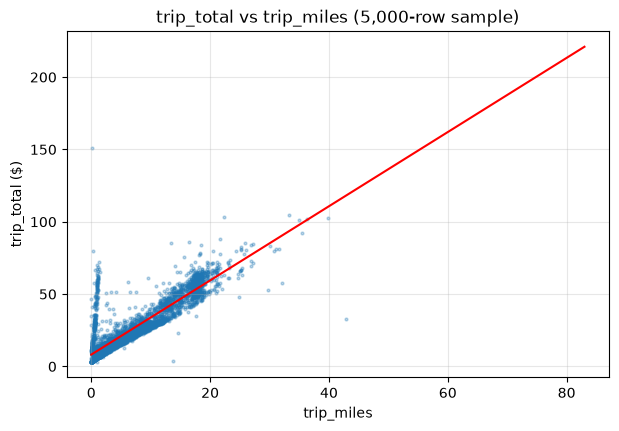

In [22]:
# check of the fit
s = data.sample(5000, random_state=1)
xs = np.linspace(0, data['trip_miles'].max(), 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(s['trip_miles'], s['trip_total'], s=4, alpha=.3)
plt.plot(xs, b0_star + b1_star * xs, 'r')
plt.xlabel('trip_miles'); plt.ylabel('trip_total ($)'); plt.title('trip_total vs trip_miles (5,000-row sample)')
plt.grid(alpha=.3); plt.show()

## Question 4b: Distance in kilometers

In [20]:
data['trip_km'] = data['trip_miles'] * 1.609
model_km = smf.ols('trip_total ~ trip_km', data=data).fit()
print(model_km.summary().tables[1])

c0, c1 = model_km.params['Intercept'], model_km.params['trip_km']
print(f"\nIntercept (km model): {c0:.6f}   vs. miles model: {b0_star:.6f}")
print(f"Slope (km model)    : {c1:.6f}   vs. miles slope / 1.609: {b1_star/1.609:.6f}")
print(f"Slope (km) * 1.609  : {c1*1.609:.6f}   vs. miles slope: {b1_star:.6f}")
print(f"R^2 (km) {model_km.rsquared:.6f}  vs  R^2 (miles) {model.rsquared:.6f}")

pred_km = model_km.predict(pd.DataFrame({'trip_km': [16.09]}))[0]
print(f"\nPredicted cost, 16.09 km: ${pred_km:.4f}")
print(f"Predicted cost, 10 miles: ${pred10:.4f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.1906      0.036    226.477      0.000       8.120       8.261
trip_km        1.5934      0.003    626.520      0.000       1.588       1.598

Intercept (km model): 8.190563   vs. miles model: 8.190563
Slope (km model)    : 1.593382   vs. miles slope / 1.609: 1.593382
Slope (km) * 1.609  : 2.563752   vs. miles slope: 2.563752
R^2 (km) 0.796969  vs  R^2 (miles) 0.796969

Predicted cost, 16.09 km: $33.8281
Predicted cost, 10 miles: $33.8281


The intercept is unchanged. 

The slope is divided by 1.609 (unit conversion).

16.09 km = 10 miles, so the prediction is the same as the 10-mile prediction from 4a. 

## Question 4c: Additional explanatory variables

In [21]:
m_tolls  = smf.ols('trip_total ~ trip_miles + tolls', data=data).fit()
m_extras = smf.ols('trip_total ~ trip_miles + extras', data=data).fit()
m_both   = smf.ols('trip_total ~ trip_miles + tolls + extras', data=data).fit()

summary = pd.DataFrame({
    'R^2': [model.rsquared, m_tolls.rsquared, m_extras.rsquared, m_both.rsquared],
    'Adj R^2': [model.rsquared_adj, m_tolls.rsquared_adj, m_extras.rsquared_adj, m_both.rsquared_adj],
}, index=['trip_miles', '+ tolls', '+ extras', '+ tolls + extras'])
display(summary)

for name, m in [('trip_miles + tolls', m_tolls), ('trip_miles + extras', m_extras),
                ('trip_miles + tolls + extras', m_both)]:
    print(f"\n{name}\n", m.params.round(4).to_string())

better = 'tolls' if m_tolls.rsquared > m_extras.rsquared else 'extras'
print(f"\nMore useful by R^2: {better}")

,R^2,Adj R^2
trip_miles,0.796969,0.796967
+ tolls,0.797020,0.797016
+ extras,0.838141,0.838138
+ tolls + extras,0.838252,0.838248



trip_miles + tolls
 Intercept    8.191000
trip_miles   2.563300
tolls        1.737900

trip_miles + extras
 Intercept    7.869300
trip_miles   2.219700
extras       2.273500

trip_miles + tolls + extras
 Intercept    7.869700
trip_miles   2.218700
tolls        2.573500
extras       2.275500

More useful by R^2: extras



In tolls vs extras, extras is the more useful explanatory variable by R^2. 

In trip_miles, tolls, and extra, R^2 is higher, R^2 does not decrease when adding addtional variables.